# Fourier series of the valve flow: $F_0$, $F_1$, $F_2$, … compared

**Setup.** One valve, flow law $F(\Delta P) = \dot m_{max}\,\hat F(u)$ with $u = \Delta P/\Delta P_{max}$ and the dimensionless shape

$$\hat F(u) = (1-u)\sqrt{u} \quad (0 \lt u \lt 1), \qquad \hat F = 0 \text{ otherwise}$$

(the thesis normalization multiplies every coefficient below by the same $c_1 = 3\sqrt3/2$; your sweep notebooks use $c_1 = 1$). During one cycle the pressure drop across the valve is $\Delta P = \Delta\bar P + \delta\cos\psi$, i.e. $u(\psi) = \bar u + \hat\delta\cos\psi$ with $\bar u = \Delta\bar P/\Delta P_{max}$ and $\hat\delta = \delta/\Delta P_{max}$. Holding $\bar u$ fixed over the cycle, $F(\psi)$ is an even periodic function, so

$$\hat F(\psi) = \hat F_0 + \hat F_1\cos\psi + \hat F_2\cos 2\psi + \ldots, \qquad \hat F_0 = \frac{1}{2\pi}\int_0^{2\pi}\hat F\,d\psi, \qquad \hat F_n = \frac{1}{\pi}\int_0^{2\pi}\hat F\cos n\psi\,d\psi$$

Everything here is dimensionless: physical coefficients are $F_n = \dot m_{max}\hat F_n(\bar u, \hat\delta)$, and the gain of the packet derivation is $N = F_1/\delta = (\dot m_{max}/\Delta P_{max})\,\hat F_1/\hat\delta$.

**Two regimes.** If the swing stays inside the open band, $\hat\delta \lt \bar u$ and $\bar u + \hat\delta \lt 1$ ("unclipped"), the coefficients have closed forms in complete elliptic integrals (section 4, derived in the companion Mathematica script and verified here). Once the swing reaches $u = 0$ or $u = 1$ the valve closes for part of the cycle and the integrals run over a sub-interval of $\psi$ — evaluated numerically here (Mathematica returns incomplete elliptic integrals).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.special import ellipk, ellipe
from numpy.polynomial import polynomial as Pn
from numpy.polynomial import chebyshev as Ch

BLUE, ORANGE, AQUA, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e8e7e3'
PSI = np.linspace(0, 2 * np.pi, 8193)[:-1]
COS = np.cos(PSI)

def Fhat(u):
    u = np.asarray(u, float); out = np.zeros_like(u)
    m = (u > 0) & (u < 1); out[m] = (1 - u[m]) * np.sqrt(u[m]); return out

def coeffs(ub, dh, nmax=5):
    """Numerical Fourier coefficients F_0 .. F_nmax of Fhat(ub + dh cos psi)."""
    y = Fhat(ub + dh * COS)
    return np.array([y.mean()] + [2.0 * (y * np.cos(n * PSI)).mean() for n in range(1, nmax + 1)])

print('example: ub = 0.65, dh = 0.20 ->', np.array2string(coeffs(0.65, 0.20), precision=5))

example: ub = 0.65, dh = 0.20 -> [ 2.67953e-01 -1.15966e-01 -1.42778e-02  6.31184e-04 -5.24766e-05
  5.33274e-06]


## 1. What the waveform looks like, and how much of it is $F_0 + F_1\cos\psi$

Four cases at the same swing $\hat\delta = 0.3$: on the rising branch ($\bar u = 0.2$), at the flow peak ($\bar u = 1/3$), on the falling branch ($\bar u = 0.65$, your outlet at the start of filling), and closed at the mean ($\bar u = 1.15$, where the valve only opens near one pressure extreme).

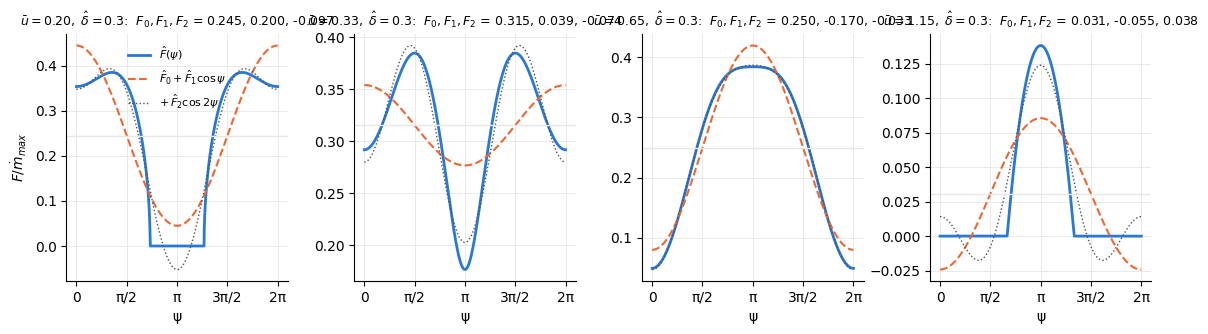

In [2]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.2)); fig.subplots_adjust(wspace=0.3)
dh = 0.3
for ax, ub in zip(axs, [0.2, 1/3, 0.65, 1.15]):
    c = coeffs(ub, dh)
    ax.plot(PSI / np.pi, Fhat(ub + dh * COS), color=BLUE, lw=2, label=r'$\hat F(\psi)$')
    ax.plot(PSI / np.pi, c[0] + c[1] * COS, color=ORANGE, lw=1.5, ls='--', label=r'$\hat F_0 + \hat F_1\cos\psi$')
    ax.plot(PSI / np.pi, c[0] + c[1] * COS + c[2] * np.cos(2 * PSI), color=INK2, lw=1, ls=':', label=r'$+\,\hat F_2\cos 2\psi$')
    ax.axhline(c[0], color=GRID, lw=1)
    ax.set_title(r'$\bar u = %.2f,\ \hat\delta = %.1f$:  $F_0, F_1, F_2$ = %.3f, %.3f, %.3f' % (ub, dh, c[0], c[1], c[2]), fontsize=9)
    ax.set_xticks([0, 0.5, 1, 1.5, 2]); ax.set_xticklabels(['0', 'π/2', 'π', '3π/2', '2π']); ax.set_xlabel('ψ')
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6)
axs[0].set_ylabel(r'$F/\dot m_{max}$'); axs[0].legend(frameon=False, fontsize=8)
plt.show()

## 2. $F_n$ against the swing, at fixed $\bar u$

Each panel is one valve position. The dotted vertical lines mark where the swing first reaches a closed end of the curve ($\hat\delta = \bar u$ reaches $u = 0$; $\hat\delta = 1 - \bar u$ reaches $u = 1$); to the left of both the closed forms of section 4 apply. Note the sign of $F_1$: negative on the falling branch (the valve feeds the oscillation), positive on the rising branch (it damps it) — and the scale of $F_2$ relative to $F_1$.

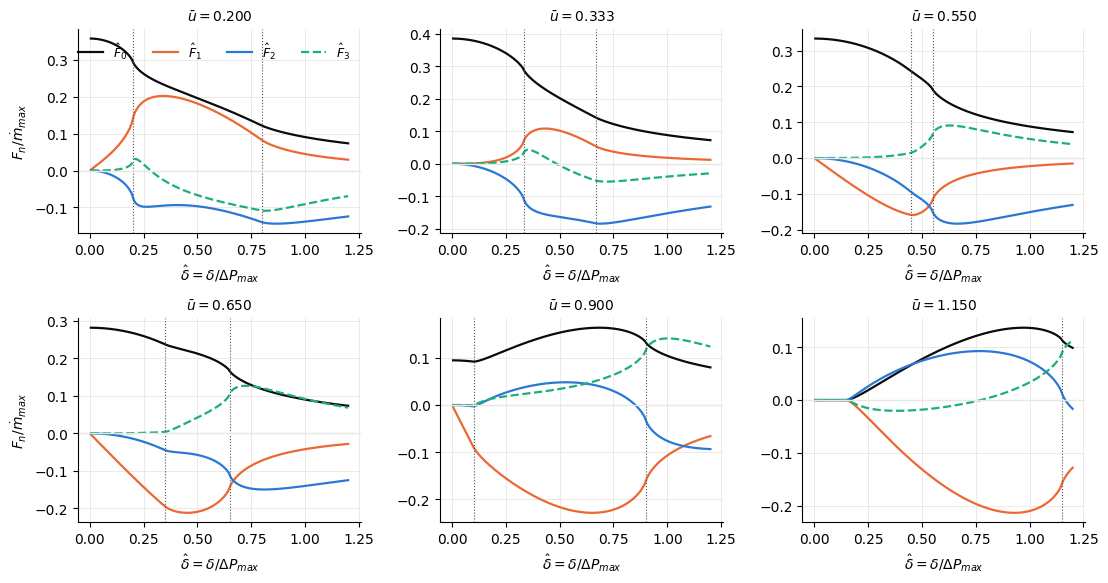

In [3]:
dhs = np.linspace(0.005, 1.2, 240)
UBS = [0.2, 1/3, 0.55, 0.65, 0.9, 1.15]
fig, axs = plt.subplots(2, 3, figsize=(13, 6.4)); fig.subplots_adjust(wspace=0.28, hspace=0.42)
for ax, ub in zip(axs.ravel(), UBS):
    C = np.array([coeffs(ub, d, 3) for d in dhs])
    for n, col, ls in [(0, INK, '-'), (1, ORANGE, '-'), (2, BLUE, '-'), (3, AQUA, '--')]:
        ax.plot(dhs, C[:, n], color=col, lw=1.6, ls=ls, label=r'$\hat F_%d$' % n)
    for xv in [ub, 1 - ub]:
        if 0 < xv < 1.2: ax.axvline(xv, color=INK2, lw=0.8, ls=':')
    ax.axhline(0, color=GRID, lw=1)
    ax.set_title(r'$\bar u = %.3f$' % ub, fontsize=10); ax.set_xlabel(r'$\hat\delta = \delta/\Delta P_{max}$')
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6)
axs[0, 0].set_ylabel(r'$F_n/\dot m_{max}$'); axs[1, 0].set_ylabel(r'$F_n/\dot m_{max}$'); axs[0, 0].legend(frameon=False, fontsize=9, ncol=4)
plt.show()

## 3. Maps over $(\bar u, \hat\delta)$

The mean $F_0$ (what charges the resonator), the first harmonic $F_1$ (what drives or damps the oscillation; its sign is the whole story of growth), the second harmonic $F_2$, and the ratio $\lvert F_2/F_1\rvert$. The white triangle is the unclipped region. The ratio is small only for small swings inside the open band; wherever the swing clips, $F_2$ is comparable to $F_1$ — and along the curve where $F_1$ changes sign the ratio is unbounded.

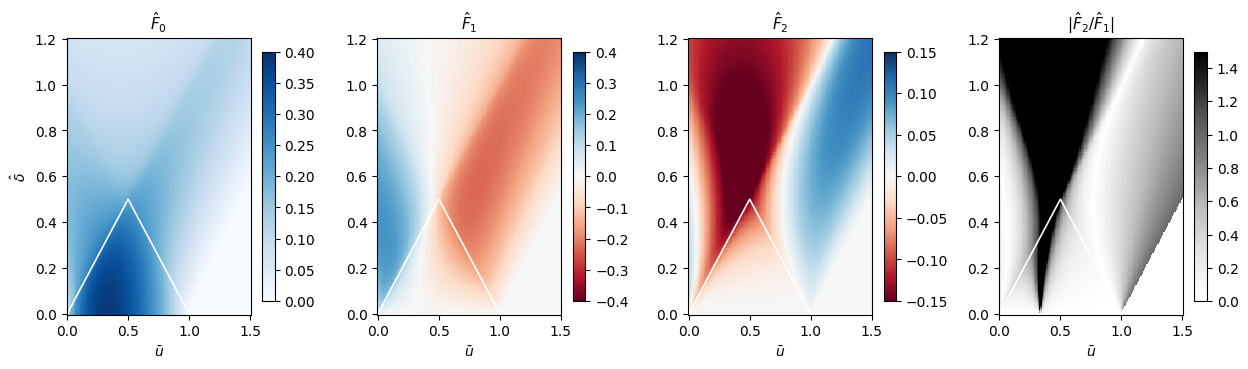

In [4]:
ub_g = np.linspace(0.0, 1.5, 151); dh_g = np.linspace(0.0, 1.2, 121)
UB, DH = np.meshgrid(ub_g, dh_g)
F0 = np.zeros_like(UB); F1 = np.zeros_like(UB); F2 = np.zeros_like(UB)
for i in range(UB.shape[0]):
    for j in range(UB.shape[1]):
        c = coeffs(UB[i, j], max(DH[i, j], 1e-6), 2); F0[i, j], F1[i, j], F2[i, j] = c
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6)); fig.subplots_adjust(wspace=0.35)
for ax, Z, ttl, cmap, vlim in [(axs[0], F0, r'$\hat F_0$', 'Blues', (0, 0.4)), (axs[1], F1, r'$\hat F_1$', 'RdBu', (-0.4, 0.4)),
                              (axs[2], F2, r'$\hat F_2$', 'RdBu', (-0.15, 0.15)), (axs[3], np.abs(F2 / np.where(np.abs(F1) < 1e-9, np.nan, F1)), r'$|\hat F_2/\hat F_1|$', 'Greys', (0, 1.5))]:
    im = ax.pcolormesh(UB, DH, Z, cmap=cmap, vmin=vlim[0], vmax=vlim[1], shading='auto')
    plt.colorbar(im, ax=ax, shrink=0.9)
    ax.plot([0, 0.5, 1], [0, 0.5, 0], color='white', lw=1.2)
    ax.set_title(ttl, fontsize=11); ax.set_xlabel(r'$\bar u$')
axs[0].set_ylabel(r'$\hat\delta$'); plt.show()

## 4. Closed forms in the unclipped region (complete elliptic integrals)

With $a = \bar u$, $b = \hat\delta$ and the swing inside the open band ($b \lt a$, $a + b \lt 1$), every coefficient reduces to the integrals $I_n = \frac{1}{2\pi}\int_0^{2\pi}\sqrt{a + b\cos\psi}\,\cos n\psi\,d\psi$ through

$$\hat F_0 = (1-\bar u)\,I_0 - \hat\delta\,I_1, \qquad \hat F_n = 2(1-\bar u)\,I_n - \hat\delta\left(I_{n-1} + I_{n+1}\right) \quad (n \ge 1)$$

(use $(1-u)\sqrt u = (1-\bar u)\sqrt{u} - \hat\delta\cos\psi\sqrt{u}$ and $\cos\psi\cos n\psi = \tfrac12[\cos(n-1)\psi + \cos(n+1)\psi]$). The $I_n$ are complete elliptic integrals of parameter $m = \dfrac{2b}{a+b}$, written $E = E(m)$, $K = K(m)$ (Mathematica's `EllipticE[m]`, `EllipticK[m]`, scipy's `ellipe(m)`, `ellipk(m)` — same convention):

$$I_0 = \frac{2\sqrt{a+b}}{\pi}\,E$$

$$I_1 = \frac{2\sqrt{a+b}}{3\pi b}\left[aE - (a-b)K\right]$$

$$I_2 = \frac{2\sqrt{a+b}}{15\pi b^2}\left[(3b^2 - 4a^2)E + 4a(a-b)K\right]$$

$$I_3 = \frac{2\sqrt{a+b}}{105\pi b^3}\left[(32a^3 - 29ab^2)E - (32a^3 - 32a^2 b - 5ab^2 + 5b^3)K\right]$$

Higher $I_n$ follow from the recurrence for $J_p = \int_0^{2\pi}(a + b\cos\psi)^p d\psi$, namely $(p+1)J_{p+1} = a(2p+1)J_p - p(a^2-b^2)J_{p-1}$ started from $J_{-1/2} = 4K/\sqrt{a+b}$ and $J_{1/2} = 4\sqrt{a+b}\,E$, with $\cos n\psi$ written as a polynomial in $(a + b\cos\psi)$. The cell below checks the closed forms against the quadrature of section 1 and, for small $\hat\delta$, against the Taylor expansions $\hat F_0 \approx \hat F + \tfrac14\hat F''\hat\delta^2$, $\hat F_1 \approx \hat F'\hat\delta + \tfrac18\hat F'''\hat\delta^3$, $\hat F_2 \approx \tfrac14\hat F''\hat\delta^2$, $\hat F_3 \approx \tfrac1{24}\hat F'''\hat\delta^3$.

In [5]:
def J_all(a, b, pmax):
    m = 2 * b / (a + b)
    J = {-0.5: 4 * ellipk(m) / np.sqrt(a + b), 0.5: 4 * np.sqrt(a + b) * ellipe(m)}
    p = 0.5
    while p + 1 <= pmax:
        J[p + 1] = (a * (2 * p + 1) * J[p] - p * (a * a - b * b) * J[p - 1]) / (p + 1); p += 1
    return J

def I_n(a, b, n):
    Tn = Ch.cheb2poly([0] * n + [1])                       # cos(n psi) as a polynomial in cos(psi)
    poly_w = np.zeros(n + 1)                               # ... rewritten in w = a + b cos(psi)
    for k, ck in enumerate(Tn):
        term = Pn.polypow([-a / b, 1 / b], k) if k > 0 else np.array([1.0]); poly_w[:len(term)] += ck * term
    J = J_all(a, b, n + 0.5)
    return sum(poly_w[k] * J[k + 0.5] for k in range(n + 1)) / (2 * np.pi)

def I_explicit(a, b):
    m = 2 * b / (a + b); E, K = ellipe(m), ellipk(m); s = np.sqrt(a + b)
    return np.array([2 * s * E / np.pi,
                     2 * s * (a * E - (a - b) * K) / (3 * np.pi * b),
                     2 * s * ((3 * b**2 - 4 * a**2) * E + 4 * a * (a - b) * K) / (15 * np.pi * b**2),
                     2 * s * ((32 * a**3 - 29 * a * b**2) * E - (32 * a**3 - 32 * a**2 * b - 5 * a * b**2 + 5 * b**3) * K) / (105 * np.pi * b**3)])

def coeffs_closed(ub, dh, nmax=3):
    assert dh < ub and ub + dh < 1, 'closed forms need the swing inside the open band'
    I = [I_n(ub, dh, n) for n in range(nmax + 2)]
    return np.array([(1 - ub) * I[0] - dh * I[1]] + [2 * (1 - ub) * I[n] - dh * (I[n - 1] + I[n + 1]) for n in range(1, nmax + 1)])

Fp = lambda u: 0.5 * u**-0.5 - 1.5 * u**0.5
Fpp = lambda u: -0.25 * u**-1.5 - 0.75 * u**-0.5
Fppp = lambda u: 0.375 * u**-2.5 + 0.375 * u**-1.5
rows = []
for ub, dh in [(0.5, 0.3), (0.65, 0.2), (0.3, 0.25), (0.6, 0.39), (0.65, 0.05), (0.2, 0.02)]:
    num, cl = coeffs(ub, dh, 3), coeffs_closed(ub, dh)
    tay = np.array([Fhat(ub) + 0.25 * Fpp(ub) * dh**2, Fp(ub) * dh + Fppp(ub) * dh**3 / 8, 0.25 * Fpp(ub) * dh**2, Fppp(ub) * dh**3 / 24])
    rows.append(dict(ub=ub, dh=dh, F0=num[0], F1=num[1], F2=num[2], F3=num[3],
                     max_err_closed_vs_quadrature=np.abs(num - cl).max(),
                     max_err_explicit_I_vs_recurrence=np.abs(I_explicit(ub, dh) - [I_n(ub, dh, n) for n in range(4)]).max(),
                     max_err_Taylor=np.abs(num - tay).max()))
df = pd.DataFrame(rows).set_index(['ub', 'dh'])
for c in [c for c in df.columns if c.startswith('max')]:
    df[c] = df[c].map(lambda v: '%.1e' % v)
df.round(5)

,,F0,F1,F2,F3,max_err_closed_vs_quadrature,max_err_explicit_I_vs_recurrence,max_err_Taylor
ub,dh,,,,,,,
0.50,0.30,0.31173,-0.09393,-0.04257,0.00431,9.0e-15,2.6e-15,2.8e-03
0.65,0.20,0.26795,-0.11597,-0.01428,0.00063,1.5e-13,1.1e-14,2.0e-04
0.30,0.25,0.33146,0.04902,-0.05470,0.01027,2.2e-15,2.5e-15,9.5e-03
0.60,0.39,0.24923,-0.18299,-0.06184,0.00661,2.2e-14,2.5e-15,4.6e-03
0.65,0.05,0.28130,-0.02943,-0.00088,0.00001,5.7e-12,4.1e-12,7.7e-07
0.20,0.02,0.35732,0.00897,-0.00045,0.00001,6.1e-13,5.6e-14,9.8e-07


## 5. At your operating states

$\Delta P_{max} = 0.458$ bar, $\dot m_{max} = 10^{-3}$ kg/s. At the start of filling ($\bar P = 5.75$ bar) the inlet sits at $\bar u_{in} = 0.545$ and the outlet at $\bar u_{out} = 0.655$; on the steady oscillation of the $V_{0,cv} = 10^{-4}$ family ($\bar P = 5.716$ bar, $\delta = 0.2945$ bar) they sit at $\bar u_{in} = 0.620$, $\bar u_{out} = 0.580$ with $\hat\delta = 0.643$. Three swings are tabulated: a small one (where the Taylor forms hold), the swing right after your kick ($\delta \approx 0.15$ bar), and the steady one. Physical coefficients in kg/s; $N = F_1/\delta$ in kg/s per bar.

In [6]:
dP_max = (6e5 - 5.45e5) / (2 * 0.6); m_max = 1e-3
cases = [('start, small swing', 0.545, 0.655, 0.05), ('start, after the kick', 0.545, 0.655, 0.15e5 / dP_max),
         ('steady oscillation', (6e5 - 5.7159e5) / dP_max, (5.7159e5 - 5.45e5) / dP_max, 0.2945e5 / dP_max)]
rows = []
for name, ui, uo, dh in cases:
    for valve, ub in [('inlet', ui), ('outlet', uo)]:
        c = coeffs(ub, dh, 3) * m_max * 1e3                    # g/s
        rows.append(dict(state=name, valve=valve, u_bar=ub, delta_hat=dh, clipped=(dh > ub) or (ub + dh > 1),
                         **{'F_%d [g/s]' % n: c[n] for n in range(4)}, **{'|F2/F1|': abs(c[2] / c[1]), '|F3/F1|': abs(c[3] / c[1])},
                         **{'N = F1/delta [g/s per bar]': c[1] / (dh * dP_max / 1e5)}))
pd.DataFrame(rows).set_index(['state', 'valve']).round(4)

u_bar  delta_hat  clipped  F_0 [g/s]  \
state                 valve                                           
start, small swing    inlet   0.5450     0.0500    False     0.3349   
                      outlet  0.6550     0.0500    False     0.2783   
start, after the kick inlet   0.5450     0.3273    False     0.2899   
                      outlet  0.6550     0.3273    False     0.2406   
steady oscillation    inlet   0.6199     0.6425     True     0.1591   
                      outlet  0.5801     0.6425     True     0.1516   

                              F_1 [g/s]  F_2 [g/s]  F_3 [g/s]  |F2/F1|  \
state                 valve                                              
start, small swing    inlet     -0.0215    -0.0010     0.0000   0.0477   
                      outlet    -0.0298    -0.0009     0.0000   0.0294   
start, after the kick inlet     -0.1277    -0.0468     0.0046   0.3667   
                      outlet    -0.1867    -0.0390     0.0029   0.2089   
steady oscillation    inlet     -0.1162    -0.1413     0.1116   1.2165   
                      outlet    -0.0850    -0.1687     0.1042   1.9835   

                              |F3/F1|  N = F1/delta [g/s per bar]  
state                 valve                                        
start, small swing    inlet    0.0006                     -0.9365  
                      outlet   0.0003                     -1.2995  
start, after the kick inlet    0.0363                     -0.8513  
                      outlet   0.0157                     -1.2444  
steady oscillation    inlet    0.9608                     -0.3945  
                      outlet   1.2255                     -0.2887

## 6. Reading the numbers

- With the swing inside the open band, $F_1 \propto \hat\delta$ while $F_2 \propto \hat\delta^2$ (sections 4 and 5): $\lvert F_2/F_1\rvert \approx \tfrac14\lvert\hat F''/\hat F'\rvert\,\hat\delta$, small for small swings — a few percent at $\hat\delta = 0.05$.
- Once the swing clips ($\hat\delta \gt \bar u$ or $\bar u + \hat\delta \gt 1$), the waveform is a pulse and $F_2$, $F_3$ are of the same order as $F_1$. Your operating states head into this regime: right after the kick ($\hat\delta = 0.33$, still unclipped but far from small) $\lvert F_2/F_1\rvert$ is already 0.2 to 0.4, and on the steady oscillation ($\hat\delta = 0.64$, clipped at both ends) it is 1.2 to 2, with $F_3$ as large as $F_1$. There is no sense in which the flow harmonics are small there.
- $F_1$ can pass through zero while $F_2$ does not (falling branch, large swing): the ratio is then meaningless, and this is exactly where the first-harmonic gain $N$ decides between growth and decay while the second harmonic sits there unchanged.
- What makes the packet solution work anyway is not the size of $F_2$ but where it goes: the resonator turns $F_2$ into a bounded ripple and $F_1$ into growth — that comparison is `higher_harmonics_check.ipynb`, not this one. This notebook only settles the coefficients themselves.
- The companion `valve_fourier_coefficients.wl` reproduces every number here in Mathematica (numerically, and symbolically in the unclipped region).